# 08 - Controlled ResNet18 Photometric Study

ToothPic | IT2226 AIDL | Reproducible Colab experiment

## Main question

Does class-independent absolute lightness randomization improve ResNet18 over conventional relative lightness jitter when everything else is held constant?

## Experimental design

- Two training arms: `relative` and `absolute`.
- Same dataset splits, cached source images, 224-pixel letterboxing, spatial augmentation, Lab a/b colour-cast randomization, architecture, initialization seed, class weights, optimizer, schedule, and evaluation transforms.
- **Only the Lab L target sampler changes**: relative +/-25 percent mean/contrast versus shared absolute targets calibrated on class-balanced training photographs.
- 24-epoch budget, 2-epoch head warmup, full fine-tuning, differential learning rates, cosine decay, AMP, early stopping, and validation macro-F1 checkpoint selection.
- Plots are generated from actual photographs. The held-out test split is evaluated only after both arms are trained. Earlier course experiments have already used this test split, so it is an internal benchmark rather than a fresh independent test.
- An optional pixel-only Random Forest probe measures **global colour and lightness statistics only**, never original width, height, file size, or aspect ratio. It is a diagnostic, **not** evidence that ResNet18 uses the same features.

## Main deliverables

1. Real relative-versus-absolute class boxplots and image previews.
2. Training / validation learning curves and optimal checkpoint epochs.
3. Clean test accuracy, macro-F1, per-class recall, confusion matrices.
4. Prediction stability under standardized lighting, colour, and blur stress.
5. A combined team model comparison from saved Drive metrics.
6. Slide-ready PNG files, CSV tables, trained checkpoints, configuration, and an honest report.

Use a **Colab GPU runtime**, then run cells in order. Source photographs and prior experiments remain unchanged.

## 1 - Colab, paths, and configuration

The group dataset is expected under the My Drive shortcut below. All outputs go into a new folder, leaving notebooks 00, 05, 05a, 06 and 07 untouched. Edit only the configuration in this cell if needed.

In [ ]:
from pathlib import Path
from google.colab import drive

drive.mount('/content/drive')

ROOT = Path('/content/drive/MyDrive/26S2-AIDL-Group-7-ToothPic')
SOURCE_DATA = ROOT / 'dataset/school_oral_training_v1'
OUT = ROOT / 'models/resnet18_controlled_study_v3'
LOCAL_DATA = Path('/content/toothpic_study_data')
OUT.mkdir(parents=True, exist_ok=True)

CONFIG = {
    'seed': 42,
    'image_size': 224,
    'jpeg_cache_quality': 95,
    'batch_size': 48,
    'epochs': 24,
    'head_warmup_epochs': 2,
    'early_stop_patience': 7,
    'early_stop_min_epochs': 12,
    'lr_backbone': 4e-5,
    'lr_head': 3e-4,
    'weight_decay': 0.01,
    'label_smoothing': 0.02,
    'grad_clip_norm': 1.0,
    'augmentation_probability': 0.90,
    'relative_jitter': 0.50,
    'calibration_images_per_class': 80,
    'calibration_quantiles': [0.05, 0.95],
    'calibration_ab_quantiles': [0.10, 0.90],
    'preview_images_per_class': 40,
    'num_workers': 2,
    'save_resume_every': 3,
    'enable_pixel_probe': True,
    'arms': ['relative', 'absolute'],
}

CLASSES = ['calculus', 'caries', 'hypodontia', 'mouth_ulcer', 'normal', 'tooth_discoloration']
PAD_COLOR = (128, 128, 128)
IMAGE_EXTS = {'.jpg', '.jpeg', '.png', '.webp', '.bmp', '.tif', '.tiff'}

assert SOURCE_DATA.is_dir(), f'Missing dataset: {SOURCE_DATA}'
for split in ['train', 'val', 'test']:
    assert (SOURCE_DATA / split).is_dir(), f'Missing split: {split}'
print('Source data:', SOURCE_DATA)
print('Output folder:', OUT)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Source data: /content/drive/MyDrive/26S2-AIDL-Group-7-ToothPic/dataset/school_oral_training_v1
Output folder: /content/drive/MyDrive/26S2-AIDL-Group-7-ToothPic/models/resnet18_controlled_study_v3


## 2 - Imports and deterministic setup

All image processing is applied to the photo **before** padding. The train and validation/test data loaders share exactly the same deterministic base image representation. GPU kernels can have small run-to-run numerical differences even with fixed seeds.

In [ ]:
import copy
import hashlib
import io
import json
import math
import os
import random
import shutil
import time
from collections import Counter
from concurrent.futures import ThreadPoolExecutor

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from PIL import Image, ImageEnhance, ImageFilter, ImageOps
from IPython.display import display
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, classification_report,
                             confusion_matrix, f1_score)
from torch import nn
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms
from torchvision.transforms import InterpolationMode
from tqdm.auto import tqdm

assert torch.cuda.is_available(), 'Switch Colab runtime to GPU before training.'
DEVICE = torch.device('cuda')
USE_AMP = True
cv2.setNumThreads(0)
torch.backends.cudnn.benchmark = True


def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


def worker_seed(worker_id):
    value = torch.initial_seed() % (2 ** 32)
    random.seed(value)
    np.random.seed(value)


def save_json(path, obj):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_text(json.dumps(obj, indent=2, sort_keys=True), encoding='ascii')


def save_fig(path):
    plt.savefig(path, dpi=180, bbox_inches='tight', facecolor='white')
    plt.show()
    plt.close()


set_seed(CONFIG['seed'])
save_json(OUT / 'config.json', CONFIG)
print('GPU:', torch.cuda.get_device_name(0))
print('PyTorch:', torch.__version__)

GPU: Tesla T4
PyTorch: 2.14.1+cu130


## 3 - Fix the input representation and cache it locally

Images in mounted Drive can be slow to read repeatedly. Here we make a single **deterministic resize-to-fit** cache in Colab's temporary storage. It preserves the full photo and aspect ratio, including EXIF orientation. Padding and photometric effects happen later.

Both training arms use exactly the same cache. The cache JPEG encoding is identical across classes and arms. It is not an extra learned feature; it is simply the cached pixel source.

The CSV manifest preserves a trace to every original image. The source data is never overwritten.

In [ ]:
def oriented_rgb(path):
    with Image.open(path) as im:
        return ImageOps.exif_transpose(im).convert('RGB')


def resize_content(image):
    return ImageOps.contain(image, (CONFIG['image_size'], CONFIG['image_size']),
                            method=Image.Resampling.LANCZOS)


def cache_one(task):
    source, dest = task
    if dest.exists() and dest.stat().st_size > 0:
        return
    dest.parent.mkdir(parents=True, exist_ok=True)
    im = resize_content(oriented_rgb(source))
    tmp = dest.with_suffix('.tmp.jpg')
    im.save(tmp, quality=CONFIG['jpeg_cache_quality'], subsampling=0)
    os.replace(tmp, dest)


manifest_rows = []
cache_tasks = []
for split in ['train', 'val', 'test']:
    for label in CLASSES:
        folder = SOURCE_DATA / split / label
        files = sorted(p for p in folder.iterdir() if p.is_file() and p.suffix.lower() in IMAGE_EXTS)
        assert files, f'No images: {folder}'
        for i, source in enumerate(files):
            cached = LOCAL_DATA / split / label / f'{i:05d}.jpg'
            cache_tasks.append((source, cached))
            manifest_rows.append({'split': split, 'label': label,
                                  'source': str(source.relative_to(SOURCE_DATA)),
                                  'cached': str(cached)})

with ThreadPoolExecutor(max_workers=8) as pool:
    list(tqdm(pool.map(cache_one, cache_tasks), total=len(cache_tasks), desc='Cache images'))

manifest = pd.DataFrame(manifest_rows)
assert len(manifest) == 3795, 'Prepared count changed. Inspect before trusting comparisons.'
assert manifest.groupby('split').size().to_dict() == {'train':3035, 'val':378, 'test':382}
manifest.to_csv(OUT / 'data_manifest.csv', index=False)
print(pd.crosstab(manifest['label'], manifest['split']).reindex(CLASSES))

Cache images:   0%|          | 0/3795 [00:00<?, ?it/s]

split                test  train  val
label                                
calculus               80    642   80
caries                 20    155   19
hypodontia            123    979  122
mouth_ulcer            25    194   24
normal                 29    227   28
tooth_discoloration   105    838  105


## 4 - Calibrate shared absolute targets from training images only

For every class, sample up to 80 **training** images. Convert each content image to OpenCV Lab. The central 25th to 75th percentiles of lightness means and standard deviations give the shared target distributions. Pooled Lab a/b target pairs provide plausible colour-cast changes without independently combining extreme red/green and blue/yellow settings.

The target is sampled without using a sample's class label. We do not deliberately erase local staining or gum colour. Scaling and clipping protections limit damage to dental structures.

In [ ]:
def content_lab(image):
    rgb = np.asarray(image.convert('RGB'))
    return cv2.cvtColor(rgb, cv2.COLOR_RGB2LAB).astype(np.float32)


def lab_summary(image):
    lab = content_lab(image)
    return {'mean_l': float(lab[:,:,0].mean()),
            'std_l': float(lab[:,:,0].std()),
            'mean_a': float(lab[:,:,1].mean()),
            'mean_b': float(lab[:,:,2].mean())}


def shared_range(values, lo_q, hi_q, min_width, min_value, max_value):
    low, high = np.quantile(values, [lo_q, hi_q])
    center = (low + high) / 2
    half_width = max((high - low) / 2, min_width / 2)
    return [float(max(min_value, center-half_width)),
            float(min(max_value, center+half_width))]


cal_rng = np.random.default_rng(CONFIG['seed'])
records = []
training = manifest[manifest.split == 'train']
for label in CLASSES:
    subset = training[training.label == label]
    chosen = cal_rng.choice(subset.index.to_numpy(),
                            size=min(CONFIG['calibration_images_per_class'], len(subset)),
                            replace=False)
    for idx in chosen:
        with Image.open(manifest.loc[idx, 'cached']) as im:
            records.append({'class':label, **lab_summary(im)})

calibration = pd.DataFrame(records)
q1, q3 = CONFIG['calibration_quantiles']
L_MEAN_RANGE = np.quantile(
    calibration['mean_l'], [q1, q3]
).astype(float).tolist()

L_STD_RANGE = np.quantile(
    calibration['std_l'], [q1, q3]
).astype(float).tolist()
aq, bq = CONFIG['calibration_ab_quantiles']
a1, a2 = np.quantile(calibration['mean_a'], [aq, bq])
b1, b2 = np.quantile(calibration['mean_b'], [aq, bq])
paired = calibration[calibration.mean_a.between(a1,a2) &
                     calibration.mean_b.between(b1,b2)]
AB_TARGETS = paired[['mean_a','mean_b']].to_numpy(dtype=np.float32)
assert len(AB_TARGETS) > 20, 'Too few Lab chroma target pairs.'

TARGETS = {'mean_l':L_MEAN_RANGE, 'std_l':L_STD_RANGE,
           'ab_targets_count':len(AB_TARGETS),
           'ab_shift_cap':None,
           'train_calibration_rows':len(calibration)}
save_json(OUT / 'calibration.json', TARGETS)
calibration.to_csv(OUT / 'calibration_samples.csv', index=False)
print(TARGETS)
display(calibration.groupby('class')[['mean_l','std_l','mean_a','mean_b']].median().round(1))

{'mean_l': [89.15493965148926, 184.74662246704102], 'std_l': [30.265694427490235, 82.5901268005371], 'ab_targets_count': 331, 'ab_shift_cap': None, 'train_calibration_rows': 480}


,mean_l,std_l,mean_a,mean_b
class,,,,
calculus,127.7,60.1,147.7,144.3
caries,145.2,46.3,147.1,140.3
hypodontia,138.4,59.9,147.0,140.1
mouth_ulcer,137.2,43.4,152.2,140.7
normal,132.9,54.9,140.4,138.0
tooth_discoloration,134.4,46.5,146.9,141.1


## 5 - Photometric methods: one controlled difference

### Relative lightness jitter

For each image, target mean and target contrast are multiplied by independent random factors in `[0.75, 1.25]`. A dark image is still generally dark; a bright one is still generally bright.

### Absolute-target lightness randomization

Sample target mean and contrast from **the same shared ranges for every class**, regardless of its original lighting. The essential transformation is:

`L_new = (L_old - mean_old) * (std_target / std_old) + mean_target`

Both arms use the **same** capped paired Lab a/b variation, clipping protection, 90% application probability, random spatial affine, and 224x224 letterbox. This isolates the lightness-target sampling strategy much more cleanly than comparing old crop-based ResNet18 with a new letterbox-based model.

In [ ]:
def shift_lab_content(content, method, rng):
    if method not in ('relative', 'absolute'):
        raise ValueError('Unknown method: ' + method)
    lab = content_lab(content)
    L = lab[:,:,0]
    A = lab[:,:,1]
    B = lab[:,:,2]
    mu = float(L.mean())
    sigma = max(float(L.std()), 1.0)

    if method == 'relative':
        j = CONFIG['relative_jitter']
        target_mean = mu * rng.uniform(1-j, 1+j)
        target_std = sigma * rng.uniform(1-j, 1+j)
    else:
        target_mean = rng.uniform(*L_MEAN_RANGE)
        target_std = rng.uniform(*L_STD_RANGE)

    scale = target_std / sigma
    lab[:, :, 0] = np.clip(
        (L - mu) * scale + target_mean,
        0, 255
    )

    # Identical global colour-cast policy for both methods.
    target_ab = AB_TARGETS[rng.integers(0, len(AB_TARGETS))]
    for channel, desired in [(1,target_ab[0]), (2,target_ab[1])]:
        old = lab[:,:,channel]
        delta = float(desired) - float(old.mean())
        lab[:,:,channel] = np.clip(old + delta, 0, 255)

    out = cv2.cvtColor(np.uint8(np.rint(np.clip(lab,0,255))), cv2.COLOR_LAB2RGB)
    return Image.fromarray(out, mode='RGB')


def letterbox(content):
    # The image is already resized-to-fit in the local cache.
    canvas = Image.new('RGB', (CONFIG['image_size'], CONFIG['image_size']), PAD_COLOR)
    x = (CONFIG['image_size'] - content.width) // 2
    y = (CONFIG['image_size'] - content.height) // 2
    canvas.paste(content, (x, y))
    return canvas


GEOMETRIC = transforms.RandomAffine(
    degrees=10,
    translate=(0.04,0.04),
    scale=(0.96,1.04),
    interpolation=InterpolationMode.BILINEAR,
    fill=PAD_COLOR)
TO_TENSOR = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize([0.485,0.456,0.406], [0.229,0.224,0.225])])


class OralDataset(Dataset):
    def __init__(self, frame, method='clean', train=False, stress=None):
        self.frame = frame.reset_index(drop=True)
        self.files = self.frame.cached.tolist()
        self.method = method
        self.train = train
        self.stress = stress
        self.names = CLASSES
        self.targets = [CLASSES.index(x) for x in self.frame.label]

    def __len__(self):
        return len(self.frame)

    def __getitem__(self, index):
        with Image.open(self.files[index]) as im:
            content = im.convert('RGB')
        if self.stress:
            content = stress_content(content, self.stress)
        if (
            self.train
            and self.method != 'no_aug'
            and np.random.random() < CONFIG['augmentation_probability']
        ):
            rng = np.random.default_rng(np.random.randint(0, 2**32-1))
            content = shift_lab_content(content, self.method, rng)

        canvas = letterbox(content)

        if self.train and self.method != 'no_aug':
            canvas = GEOMETRIC(canvas)
        return TO_TENSOR(canvas), self.targets[index]


def loader_for(frame, method='clean', train=False, stress=None, seed=42):
    dataset = OralDataset(frame, method=method, train=train, stress=stress)
    generator = torch.Generator().manual_seed(seed)
    return DataLoader(dataset, batch_size=CONFIG['batch_size'], shuffle=train,
                      num_workers=CONFIG['num_workers'], pin_memory=True,
                      worker_init_fn=worker_seed, generator=generator)


# Sanity check that the same input geometry and labels reach both arms.
sample = training.iloc[0]
with Image.open(sample.cached) as im:
    sample_image = im.convert('RGB')
for method in CONFIG['arms']:
    styled = shift_lab_content(sample_image, method, np.random.default_rng(123))
    assert letterbox(styled).size == (224,224)
print('Both methods passed the image-shape sanity check.')

Both methods passed the image-shape sanity check.


/tmp/ipykernel_2085/430360422.py:33: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  return Image.fromarray(out, mode='RGB')


## 6 - Real-data visuals for the presentation

Each box is built from **actual training photographs**, using the same source images and the same y-axis. Diamond markers show each class's clean median. This demonstrates how the methods affect global brightness statistics. It does **not** measure classification accuracy.

The preview contact sheet lets you visually check whether caries, staining and gum colour remain recognizable. Stop and adjust the augmentation if the results visibly destroy useful features.

/tmp/ipykernel_2085/430360422.py:33: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  return Image.fromarray(out, mode='RGB')


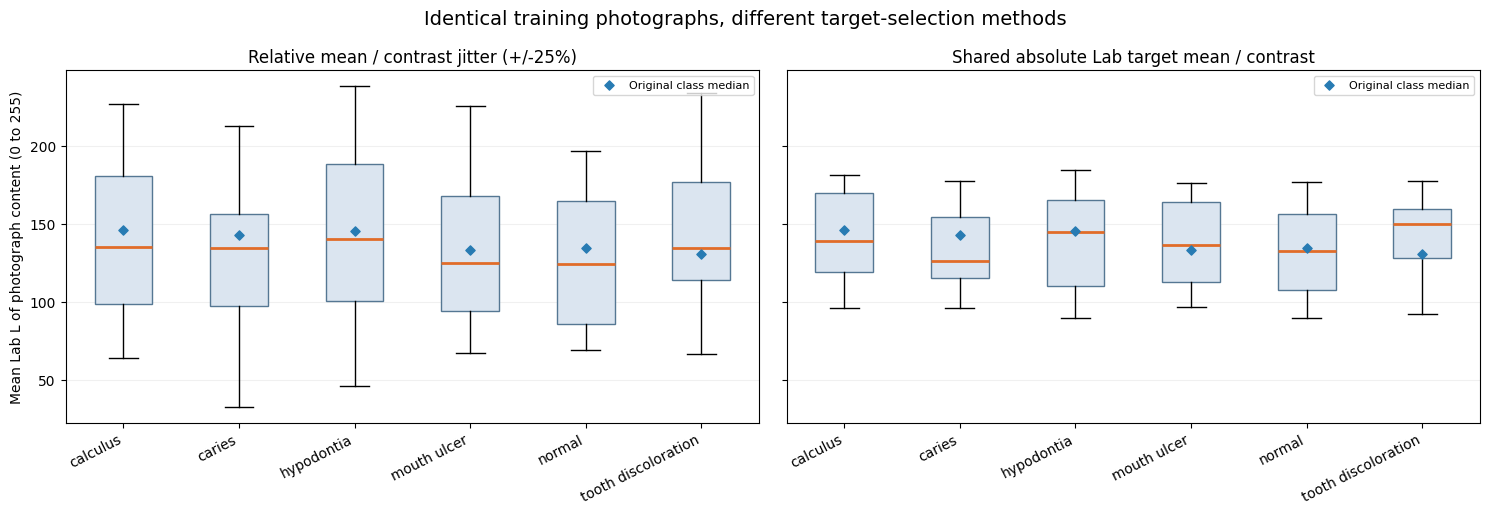

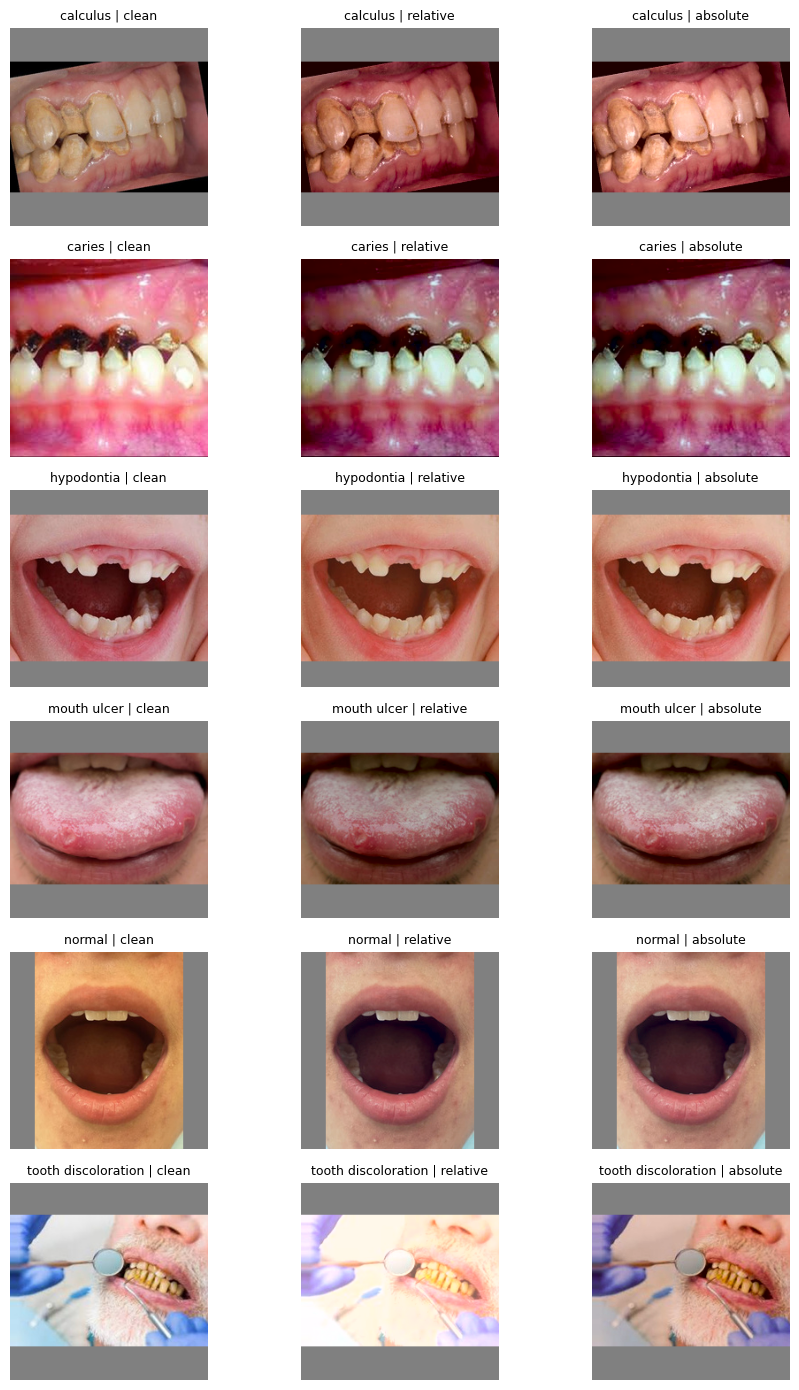

In [ ]:
plot_rows = []
preview_samples = []
plot_rng = np.random.default_rng(191)
for label in CLASSES:
    subset = training[training.label == label]
    choice = plot_rng.choice(subset.index.to_numpy(),
                             min(CONFIG['preview_images_per_class'],len(subset)),
                             replace=False)
    for i, idx in enumerate(choice):
        path = manifest.loc[idx,'cached']
        with Image.open(path) as im:
            source = im.convert('RGB')
        for method in ['clean','relative','absolute']:
            view = source if method == 'clean' else shift_lab_content(
                source, method, np.random.default_rng(100000 + int(idx)))
            plot_rows.append({'class':label,'method':method,
                              'mean_l':lab_summary(view)['mean_l']})
            if i == 0:
                preview_samples.append({'class':label,'method':method,'image':letterbox(view)})

plot_df = pd.DataFrame(plot_rows)
plot_df.to_csv(OUT / 'brightness_distributions.csv',index=False)
clean_medians = plot_df[plot_df.method=='clean'].groupby('class').mean_l.median().reindex(CLASSES)
fig, axes = plt.subplots(1,2,figsize=(15,5.2),sharey=True)
for ax, method, label in zip(axes,['relative','absolute'],
                             ['Relative mean / contrast jitter (+/-25%)',
                              'Shared absolute Lab target mean / contrast']):
    groups = [plot_df[(plot_df.method==method)&(plot_df['class']==c)].mean_l.values
              for c in CLASSES]
    ax.boxplot(groups,patch_artist=True,showfliers=True,
               boxprops={'facecolor':'#dbe5f0','edgecolor':'#557793'},
               medianprops={'color':'#e16c29','linewidth':2})
    ax.scatter(range(1,7),clean_medians.values,marker='D',s=22,color='#277bb3',
               label='Original class median',zorder=4)
    ax.set_xticks(range(1,7),[c.replace('_',' ') for c in CLASSES],rotation=27,ha='right')
    ax.set_title(label,fontsize=12)
    ax.grid(axis='y',alpha=0.18)
    ax.legend(fontsize=8,loc='upper right')
axes[0].set_ylabel('Mean Lab L of photograph content (0 to 255)')
fig.suptitle('Identical training photographs, different target-selection methods',fontsize=14)
fig.tight_layout()
save_fig(OUT/'slide_01_relative_vs_absolute_boxplots.png')

fig, axes = plt.subplots(len(CLASSES),3,figsize=(9.5,14))
for i,label in enumerate(CLASSES):
    for j,method in enumerate(['clean','relative','absolute']):
        item = next(x for x in preview_samples if x['class']==label and x['method']==method)
        axes[i,j].imshow(item['image'])
        axes[i,j].set_title(label.replace('_',' ')+' | '+method,fontsize=9)
        axes[i,j].axis('off')
plt.tight_layout()
save_fig(OUT/'slide_02_augmentation_previews.png')

## 7 - Optional pixel-only Random Forest diagnostic

This probe has **none** of the original file size, width, height or aspect-ratio features. It uses global Lab/RGB/saturation statistics extracted from actual photo content. Its purpose is to check whether a cheap pixel-statistic classifier can still predict classes after each transform.

We use one independently randomized view per photo for each arm, fit on TRAIN and evaluate on VALIDATION. Results are diagnostic because some global colour genuinely carries dental information. A lower score is not automatically better and **does not prove what a CNN learns**.

In [ ]:
def pixel_features(image):
    rgb = np.asarray(image).astype(np.uint8)
    lab = cv2.cvtColor(rgb,cv2.COLOR_RGB2LAB)
    hsv = cv2.cvtColor(rgb,cv2.COLOR_RGB2HSV)
    return [float(rgb[:,:,0].mean()),float(rgb[:,:,1].mean()),float(rgb[:,:,2].mean()),
            float(lab[:,:,0].mean()),float(lab[:,:,0].std()),
            float(lab[:,:,1].mean()),float(lab[:,:,2].mean()),
            float(hsv[:,:,1].mean())]


def stable_rng(source_key, method):
    digest = hashlib.sha256((source_key+'|'+method+'|19284').encode('utf-8')).digest()
    return np.random.default_rng(int.from_bytes(digest[:8],'little'))


def one_probe_split(frame, method):
    rows=[]
    for row in tqdm(frame.itertuples(index=False),total=len(frame),desc='Probe '+method):
        with Image.open(row.cached) as im:
            source=im.convert('RGB')
        content=shift_lab_content(source,method,stable_rng(row.source,method))
        rows.append(pixel_features(content))
    return np.asarray(rows,dtype=np.float32)


if CONFIG['enable_pixel_probe']:
    probe_results=[]
    val_frame=manifest[manifest.split=='val']
    for method in CONFIG['arms']:
        X_train=one_probe_split(training,method)
        X_val=one_probe_split(val_frame,method)
        clf=RandomForestClassifier(n_estimators=250,min_samples_leaf=2,
                class_weight='balanced_subsample',random_state=CONFIG['seed'],n_jobs=-1)
        clf.fit(X_train,training.label)
        prediction=clf.predict(X_val)
        probe_results.append({'method':method,
                              'val_accuracy':accuracy_score(val_frame.label,prediction),
                              'val_macro_f1':f1_score(val_frame.label,prediction,
                                                labels=CLASSES,average='macro',zero_division=0),
                              'features':'RGB means, Lab means/std, saturation; no metadata'})
    probe_df=pd.DataFrame(probe_results)
    probe_df.to_csv(OUT/'pixel_only_rf_validation.csv',index=False)
    display(probe_df)
    print('Interpretation: These are global pixel-statistic correlations, not CNN explanations.')

Probe relative:   0%|          | 0/3035 [00:00<?, ?it/s]

/tmp/ipykernel_2085/430360422.py:33: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  return Image.fromarray(out, mode='RGB')


Probe relative:   0%|          | 0/378 [00:00<?, ?it/s]

Probe absolute:   0%|          | 0/3035 [00:00<?, ?it/s]

/tmp/ipykernel_2085/430360422.py:33: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  return Image.fromarray(out, mode='RGB')


Probe absolute:   0%|          | 0/378 [00:00<?, ?it/s]

,method,val_accuracy,val_macro_f1,features
0,relative,0.349206,0.185468,"RGB means, Lab means/std, saturation; no metadata"
1,absolute,0.320106,0.197468,"RGB means, Lab means/std, saturation; no metadata"


Interpretation: These are global pixel-statistic correlations, not CNN explanations.


## 8 - Training utilities

Training uses:

- ImageNet-pretrained ResNet18, new `Linear(512, 6)` head.
- First 2 epochs: train the new head while freezing the pretrained backbone.
- Remaining epochs: fine-tune all layers with lower backbone learning rate.
- Inverse-square-root class weights and small label smoothing.
- AdamW, cosine learning-rate decay, AMP, gradient clipping.
- Save best checkpoint by validation macro-F1, not by test results.
- An automatic `last.pt` checkpoint every few epochs for Colab interruption recovery.

These improvements are held identical between both arms. Thus the study is still a controlled augmentation comparison, not a hyperparameter fishing expedition.

In [ ]:
def build_resnet(pretrained=True):
    weights = models.ResNet18_Weights.DEFAULT if pretrained else None
    model = models.resnet18(weights=weights)
    model.fc = nn.Linear(model.fc.in_features, len(CLASSES))
    return model.to(DEVICE)


def build_training_objects(model):
    counts=training.label.value_counts().reindex(CLASSES).to_numpy(dtype=np.float32)
    weights=1.0/np.sqrt(counts)
    weights=weights/weights.mean()
    loss_fn=nn.CrossEntropyLoss(
        weight=torch.tensor(weights,dtype=torch.float32,device=DEVICE),
        label_smoothing=CONFIG['label_smoothing'])
    backbone=[p for name,p in model.named_parameters() if not name.startswith('fc.')]
    optimizer=torch.optim.AdamW([
        {'params':backbone,'lr':CONFIG['lr_backbone']},
        {'params':list(model.fc.parameters()),'lr':CONFIG['lr_head']}],
        weight_decay=CONFIG['weight_decay'])
    scheduler=torch.optim.lr_scheduler.CosineAnnealingLR(
        optimizer, T_max=max(1,CONFIG['epochs']-CONFIG['head_warmup_epochs']),
        eta_min=2e-6)
    scaler=torch.amp.GradScaler('cuda',enabled=USE_AMP)
    return loss_fn, optimizer, scheduler, scaler


def set_backbone_trainable(model, enabled):
    for name,param in model.named_parameters():
        if not name.startswith('fc.'):
            param.requires_grad=enabled
    model.fc.requires_grad_(True)


def run_epoch(model, loader, loss_fn, optimizer=None, scaler=None, head_only=False):
    training=optimizer is not None
    model.train(training)
    if head_only and training:
        # BatchNorm running statistics should stay fixed during head-only warmup.
        for module in model.modules():
            if isinstance(module,nn.BatchNorm2d):
                module.eval()
    loss_total=0.0
    true=[]
    pred=[]
    for images,labels in tqdm(loader,leave=False,disable=not training):
        images=images.to(DEVICE,non_blocking=True)
        labels=labels.to(DEVICE,non_blocking=True)
        if training:
            optimizer.zero_grad(set_to_none=True)
        with torch.set_grad_enabled(training):
            with torch.autocast(device_type='cuda',dtype=torch.float16,enabled=USE_AMP):
                logits=model(images)
                loss=loss_fn(logits,labels)
            if training:
                scaler.scale(loss).backward()
                scaler.unscale_(optimizer)
                nn.utils.clip_grad_norm_(model.parameters(),CONFIG['grad_clip_norm'])
                scaler.step(optimizer)
                scaler.update()
        loss_total+=float(loss.item())*len(labels)
        true.extend(labels.cpu().numpy().tolist())
        pred.extend(logits.argmax(1).detach().cpu().numpy().tolist())
    return {'loss':loss_total/len(loader.dataset),
            'macro_f1':f1_score(true,pred,average='macro',labels=range(len(CLASSES)),zero_division=0),
            'accuracy':accuracy_score(true,pred)}


def checkpoint_payload(model,optimizer,scheduler,scaler,history,epoch,best,bad,arm):
    return {'model':model.state_dict(), 'optimizer':optimizer.state_dict(),
            'scheduler':scheduler.state_dict(), 'scaler':scaler.state_dict(),
            'epoch':epoch, 'best_val_f1':best, 'bad_epochs':bad,
            'history':history, 'arm':arm, 'classes':CLASSES, 'config':CONFIG}


def train_arm(arm):
    folder=OUT / arm
    folder.mkdir(parents=True,exist_ok=True)
    best_path=folder/'best.pt'
    last_path=folder/'last.pt'
    final_flag=folder/'finished.json'
    if final_flag.exists() and best_path.exists():
        completed = json.loads(final_flag.read_text(encoding='ascii'))
        assert completed['config'] == CONFIG, 'Config changed. Use a different OUT folder.'
        print('Already completed:',arm)
        return pd.read_csv(folder/'history.csv')

    set_seed(CONFIG['seed'])
    model=build_resnet()
    loss_fn,optimizer,scheduler,scaler=build_training_objects(model)
    train_loader=loader_for(training,method=arm,train=True,seed=CONFIG['seed'])
    val_loader=loader_for(manifest[manifest.split=='val'],seed=CONFIG['seed']+1)
    history=[]
    best=-1.0
    bad=0
    start_epoch=1
    if last_path.exists():
        state=torch.load(last_path,map_location='cpu',weights_only=False)
        assert state['arm']==arm and state['config']==CONFIG, 'Saved config does not match current run.'
        model.load_state_dict(state['model'])
        optimizer.load_state_dict(state['optimizer'])
        scheduler.load_state_dict(state['scheduler'])
        scaler.load_state_dict(state['scaler'])
        history=state['history']
        best=state['best_val_f1']
        bad=state['bad_epochs']
        start_epoch=state['epoch']+1
        print('Resuming',arm,'from epoch',start_epoch)

    start_time=time.time()
    for epoch in range(start_epoch,CONFIG['epochs']+1):
        head_only=epoch<=CONFIG['head_warmup_epochs']
        set_backbone_trainable(model,not head_only)
        train_stats=run_epoch(model,train_loader,loss_fn,optimizer,scaler,head_only)
        val_stats=run_epoch(model,val_loader,loss_fn)
        if not head_only:
            scheduler.step()
        row={'epoch':epoch,'phase':'head' if head_only else 'full',
             'train_loss':train_stats['loss'],'val_loss':val_stats['loss'],
             'train_macro_f1':train_stats['macro_f1'],
             'val_macro_f1':val_stats['macro_f1'],
             'val_accuracy':val_stats['accuracy'],
             'lr_backbone':optimizer.param_groups[0]['lr'],
             'lr_head':optimizer.param_groups[1]['lr']}
        history.append(row)
        score=val_stats['macro_f1']
        if score>best+1e-5:
            best=score
            bad=0
            torch.save({'model':model.state_dict(),'arm':arm,'epoch':epoch,
                        'best_val_f1':best,'classes':CLASSES,'config':CONFIG},best_path)
        else:
            bad+=1
        pd.DataFrame(history).to_csv(folder/'history.csv',index=False)
        print(f'{arm:8s} | epoch {epoch:02d}/{CONFIG["epochs"]} | '
              f'train F1 {train_stats["macro_f1"]:.4f} | '
              f'val F1 {score:.4f} | best {best:.4f} | '
              f'val loss {val_stats["loss"]:.3f}')
        if epoch%CONFIG['save_resume_every']==0:
            torch.save(checkpoint_payload(model,optimizer,scheduler,scaler,
                                          history,epoch,best,bad,arm),last_path)
        if epoch>=CONFIG['early_stop_min_epochs'] and bad>=CONFIG['early_stop_patience']:
            print('Early stopping after',epoch,'epochs.')
            break

    assert best_path.exists()
    df=pd.DataFrame(history)
    best_epoch=int(df.loc[df.val_macro_f1.idxmax(),'epoch'])
    summary={'arm':arm,'epochs_completed':int(df.epoch.max()),
             'best_val_macro_f1':float(best), 'best_epoch':best_epoch,
             'runtime_minutes':round((time.time()-start_time)/60,2),
             'config':CONFIG}
    save_json(final_flag,summary)
    print('Finished:',summary)
    return df

## 9 - Run both controlled training arms

Both arms start from the same seeded ImageNet initialization. **Do not change settings between arms.** This is the expensive cell. The two model folders are saved separately, and completed arms are skipped on rerun.


TRAINING: relative


/tmp/ipykernel_2085/430360422.py:33: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  return Image.fromarray(out, mode='RGB')


  0%|          | 0/64 [00:00<?, ?it/s]

/tmp/ipykernel_2085/430360422.py:33: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  return Image.fromarray(out, mode='RGB')
/tmp/ipykernel_2085/430360422.py:33: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  return Image.fromarray(out, mode='RGB')
/tmp/ipykernel_2085/430360422.py:33: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  return Image.fromarray(out, mode='RGB')


relative | epoch 01/24 | train F1 0.3569 | val F1 0.4793 | best 0.4793 | val loss 1.275


/tmp/ipykernel_2085/430360422.py:33: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  return Image.fromarray(out, mode='RGB')


... (147 outputs left out)

  0%|          | 0/64 [00:00<?, ?it/s]

no_aug   | epoch 15/24 | train F1 1.0000 | val F1 0.9422 | best 0.9565 | val loss 0.256


  0%|          | 0/64 [00:00<?, ?it/s]

no_aug   | epoch 16/24 | train F1 1.0000 | val F1 0.9561 | best 0.9565 | val loss 0.249
Early stopping after 16 epochs.
Finished: {'arm': 'no_aug', 'epochs_completed': 16, 'best_val_macro_f1': 0.9564659980812813, 'best_epoch': 9, 'runtime_minutes': 6.27, 'config': {'seed': 42, 'image_size': 224, 'jpeg_cache_quality': 95, 'batch_size': 48, 'epochs': 24, 'head_warmup_epochs': 2, 'early_stop_patience': 7, 'early_stop_min_epochs': 12, 'lr_backbone': 4e-05, 'lr_head': 0.0003, 'weight_decay': 0.01, 'label_smoothing': 0.02, 'grad_clip_norm': 1.0, 'augmentation_probability': 0.9, 'relative_jitter': 0.5, 'calibration_images_per_class': 80, 'calibration_quantiles': [0.05, 0.95], 'calibration_ab_quantiles': [0.1, 0.9], 'preview_images_per_class': 40, 'num_workers': 2, 'save_resume_every': 3, 'enable_pixel_probe': True, 'arms': ['relative', 'absolute']}}


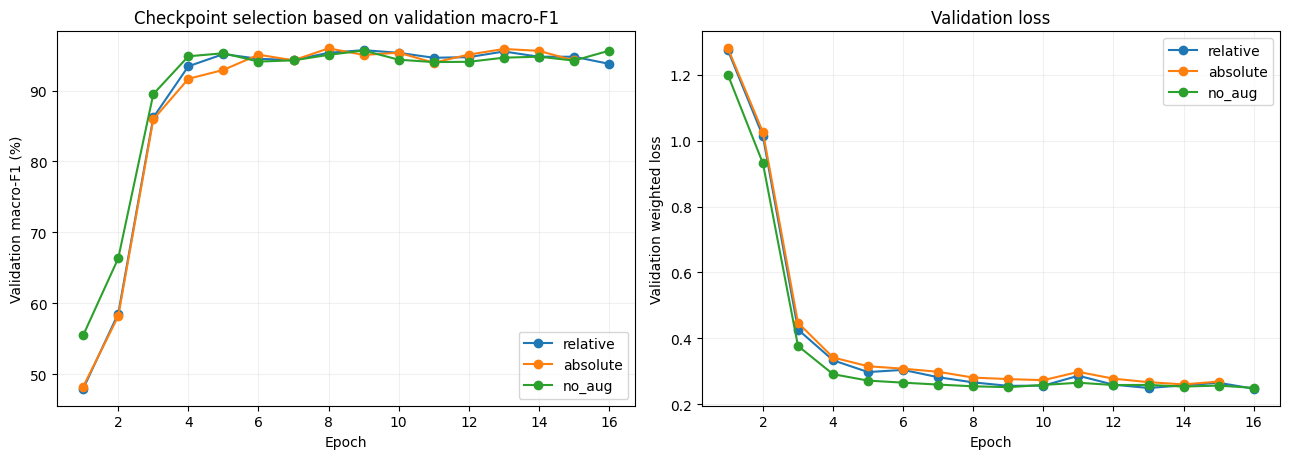

In [ ]:
histories={}
for arm in CONFIG['arms']:
    print('\n'+'='*60+'\nTRAINING: '+arm+'\n'+'='*60)
    histories[arm]=train_arm(arm)

print('\n' + '=' * 60 + '\nTRAINING: no_aug\n' + '=' * 60)
histories['no_aug'] = train_arm('no_aug')

fig,axes=plt.subplots(1,2,figsize=(13,4.7))
for arm,h in histories.items():
    axes[0].plot(h.epoch,h.val_macro_f1*100,marker='o',label=arm)
    axes[1].plot(h.epoch,h.val_loss,marker='o',label=arm)
axes[0].set_ylabel('Validation macro-F1 (%)')
axes[1].set_ylabel('Validation weighted loss')
for ax in axes:
    ax.set_xlabel('Epoch')
    ax.grid(alpha=.18)
    ax.legend()
axes[0].set_title('Checkpoint selection based on validation macro-F1')
axes[1].set_title('Validation loss')
plt.tight_layout()
save_fig(OUT/'slide_03_validation_learning_curves.png')

## 10 - Select the winner using validation, not test

The objective is high **validation macro-F1** across six imbalanced classes. This cell chooses a winner before the held-out test results are computed. Validation and test preprocessing are deterministic, shared, and free of random colour modifications.

In [ ]:
val_results=[]
for arm in CONFIG['arms']:
    h=pd.read_csv(OUT/arm/'history.csv')
    row=h.loc[h.val_macro_f1.idxmax()]
    val_results.append({'arm':arm,'best_epoch':int(row.epoch),
                        'best_val_macro_f1':float(row.val_macro_f1),
                        'best_val_accuracy':float(row.val_accuracy)})
val_table=pd.DataFrame(val_results).sort_values('best_val_macro_f1',ascending=False)
WINNER=str(val_table.iloc[0].arm)
val_table.to_csv(OUT/'validation_selection.csv',index=False)
save_json(OUT/'selected_model.json',{'selected_by':'validation_macro_f1','winner':WINNER,
                                     'comparison':val_results})
display(val_table)
print('Selected winner by validation macro-F1:',WINNER)

,arm,best_epoch,best_val_macro_f1,best_val_accuracy
1,absolute,8,0.959499,0.973545
0,relative,9,0.956964,0.978836


Selected winner by validation macro-F1: absolute


## 11 - Evaluate the held-out school test split once

This test set has been used by earlier project experiments, so do **not** call it an independent-patient or unseen-device evaluation. Both models get exactly the same **deterministic letterboxed** test images. We report accuracy, macro-F1, per-class recall and confusion matrices, then run the same fixed stress conditions for both models.

Prediction flip rate is the proportion of the **same source photos** whose predicted class changes after a photographic perturbation. Lower flip rate indicates improved prediction stability, not necessarily better clinical accuracy.

relative clean:   0%|          | 0/8 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x78f9f1edd940>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process


relative dim_070:   0%|          | 0/8 [00:00<?, ?it/s]

relative bright_130:   0%|          | 0/8 [00:00<?, ?it/s]

/tmp/ipykernel_2085/288194065.py:26: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  return Image.fromarray(np.uint8(np.clip(a,0,255)),mode='RGB')
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x78f9f1edd940>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x78f9f1edd940>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line

relative warm:   0%|          | 0/8 [00:00<?, ?it/s]

... (28 outputs left out)

CLEAN TEST


,arm,condition,accuracy,macro_f1,flip_rate
0,relative,clean,0.952880,0.915342,0.0
9,absolute,clean,0.955497,0.919307,0.0


STRESS TEST


accuracy           flip_rate          
arm           absolute  relative  absolute  relative
condition                                           
blur_12       0.882199  0.861257  0.104712  0.138743
bright_130    0.947644  0.950262  0.023560  0.026178
cool          0.945026  0.947644  0.020942  0.015707
dim_070       0.950262  0.955497  0.020942  0.023560
green_cast    0.955497  0.947644  0.020942  0.020942
magenta_cast  0.952880  0.952880  0.018325  0.023560
uneven_light  0.947644  0.952880  0.018325  0.013089
warm          0.950262  0.952880  0.023560  0.013089

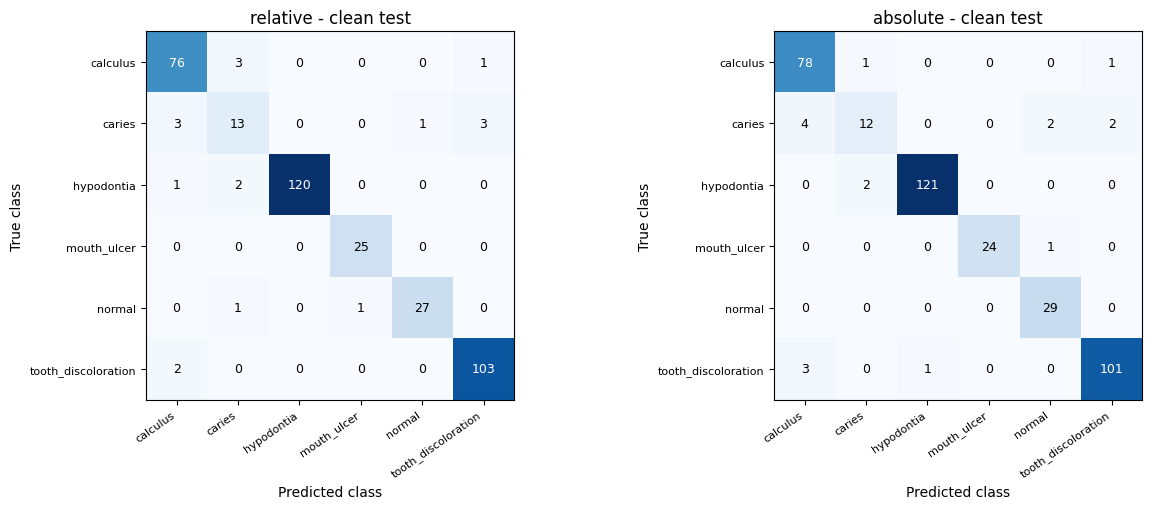

In [ ]:
STRESSES=['dim_070','bright_130','warm','cool','green_cast',
          'magenta_cast','blur_12','uneven_light']


def stress_content(content, mode):
    if mode == 'dim_070':
        return ImageEnhance.Brightness(content).enhance(0.70)
    if mode == 'bright_130':
        return ImageEnhance.Brightness(content).enhance(1.30)
    if mode == 'blur_12':
        return content.filter(ImageFilter.GaussianBlur(1.2))
    a=np.asarray(content).astype(np.float32)
    if mode == 'warm':
        a*=np.array([1.12,1.0,0.88],dtype=np.float32)
    elif mode == 'cool':
        a*=np.array([0.88,1.0,1.12],dtype=np.float32)
    elif mode == 'green_cast':
        a*=np.array([0.96,1.10,0.96],dtype=np.float32)
    elif mode == 'magenta_cast':
        a*=np.array([1.04,0.90,1.04],dtype=np.float32)
    elif mode == 'uneven_light':
        gradient=np.linspace(0.72,1.13,a.shape[1],dtype=np.float32)
        a*=gradient[None,:,None]
    else:
        raise ValueError('Unknown stress: '+mode)
    return Image.fromarray(np.uint8(np.clip(a,0,255)),mode='RGB')


@torch.inference_mode()
def predict_checkpoint(arm,stress=None):
    model=build_resnet(pretrained=False)
    saved=torch.load(OUT/arm/'best.pt',map_location=DEVICE,weights_only=False)
    assert saved['arm']==arm and saved['classes']==CLASSES
    model.load_state_dict(saved['model'])
    model.eval()
    loader=loader_for(manifest[manifest.split=='test'],train=False,stress=stress,seed=112)
    true=[]
    preds=[]
    probs=[]
    for images,labels in tqdm(loader,leave=False,desc=f'{arm} {stress or "clean"}'):
        images=images.to(DEVICE,non_blocking=True)
        with torch.autocast(device_type='cuda',dtype=torch.float16,enabled=USE_AMP):
            logits=model(images)
        p=torch.softmax(logits.float(),dim=1).cpu().numpy()
        probs.append(p)
        true.extend(labels.numpy().tolist())
        preds.extend(p.argmax(axis=1).tolist())
    del model
    torch.cuda.empty_cache()
    return np.asarray(true),np.asarray(preds),np.concatenate(probs,axis=0)


test_rows=[]
per_class=[]
all_predictions=[]
conf_matrices={}
for arm in CONFIG['arms']:
    true,clean_pred,clean_prob=predict_checkpoint(arm)
    clean_f1=f1_score(true,clean_pred,average='macro',zero_division=0)
    clean_acc=accuracy_score(true,clean_pred)
    conf_matrices[arm]=confusion_matrix(true,clean_pred,labels=range(len(CLASSES)))
    test_rows.append({'arm':arm,'condition':'clean','accuracy':clean_acc,
                      'macro_f1':clean_f1,'flip_rate':0.0})
    report=classification_report(true,clean_pred,labels=range(len(CLASSES)),
                                 target_names=CLASSES,output_dict=True,zero_division=0)
    for label in CLASSES:
        per_class.append({'arm':arm,'class':label,'support':report[label]['support'],
                          'precision':report[label]['precision'],
                          'recall':report[label]['recall'],
                          'f1':report[label]['f1-score']})
    for condition in STRESSES:
        y,stressed_pred,prob=predict_checkpoint(arm,condition)
        assert np.array_equal(y,true)
        test_rows.append({'arm':arm,'condition':condition,
                          'accuracy':accuracy_score(y,stressed_pred),
                          'macro_f1':f1_score(y,stressed_pred,average='macro',zero_division=0),
                          'flip_rate':float(np.mean(stressed_pred!=clean_pred))})
    for i,(a,p) in enumerate(zip(true,clean_pred)):
        all_predictions.append({'arm':arm,'row_index':i,'true':CLASSES[a],
                                'prediction':CLASSES[p],
                                'confidence':float(clean_prob[i,p]),
                                'correct':bool(a==p)})

scores=pd.DataFrame(test_rows)
recalls=pd.DataFrame(per_class)
scores.to_csv(OUT/'test_and_stress_scores.csv',index=False)
recalls.to_csv(OUT/'test_per_class.csv',index=False)
pd.DataFrame(all_predictions).to_csv(OUT/'clean_predictions.csv',index=False)
print('CLEAN TEST')
display(scores[scores.condition=='clean'])
print('STRESS TEST')
display(scores[scores.condition!='clean'].pivot(index='condition',columns='arm',
                                             values=['accuracy','flip_rate']))

fig,axes=plt.subplots(1,2,figsize=(13,5.2))
for ax,arm in zip(axes,CONFIG['arms']):
    cm=conf_matrices[arm]
    ax.imshow(cm,cmap='Blues')
    for i in range(6):
        for j in range(6):
            ax.text(j,i,str(cm[i,j]),ha='center',va='center',fontsize=9,
                    color='white' if cm[i,j]>(cm.max()/2) else 'black')
    ax.set_xticks(range(6),CLASSES,rotation=35,ha='right',fontsize=8)
    ax.set_yticks(range(6),CLASSES,fontsize=8)
    ax.set_xlabel('Predicted class')
    ax.set_ylabel('True class')
    ax.set_title(arm+' - clean test')
plt.tight_layout()
save_fig(OUT/'slide_04_test_confusion_matrices.png')

no_aug clean:   0%|          | 0/8 [00:00<?, ?it/s]

no_aug dim_070:   0%|          | 0/8 [00:00<?, ?it/s]

no_aug bright_130:   0%|          | 0/8 [00:00<?, ?it/s]

/tmp/ipykernel_2085/288194065.py:26: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  return Image.fromarray(np.uint8(np.clip(a,0,255)),mode='RGB')


no_aug warm:   0%|          | 0/8 [00:00<?, ?it/s]

/tmp/ipykernel_2085/288194065.py:26: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  return Image.fromarray(np.uint8(np.clip(a,0,255)),mode='RGB')
/tmp/ipykernel_2085/288194065.py:26: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  return Image.fromarray(np.uint8(np.clip(a,0,255)),mode='RGB')
/tmp/ipykernel_2085/288194065.py:26: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  return Image.fromarray(np.uint8(np.clip(a,0,255)),mode='RGB')
/tmp/ipykernel_2085/288194065.py:26: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  return Image.fromarray(np.uint8(np.clip(a,0,255)),mode='RGB')


... (12 outputs left out)

HELD-OUT SCHOOL TEST (for reporting)


,arm,accuracy,macro_f1
18,no_aug,0.958115,0.930087
9,absolute,0.955497,0.919307
0,relative,0.952880,0.915342


STRESS ROBUSTNESS


,mean_stress_accuracy,worst_stress_accuracy,mean_flip_rate
arm,,,
no_aug,0.943063,0.882199,0.028141
relative,0.940118,0.861257,0.034359
absolute,0.941427,0.882199,0.031414


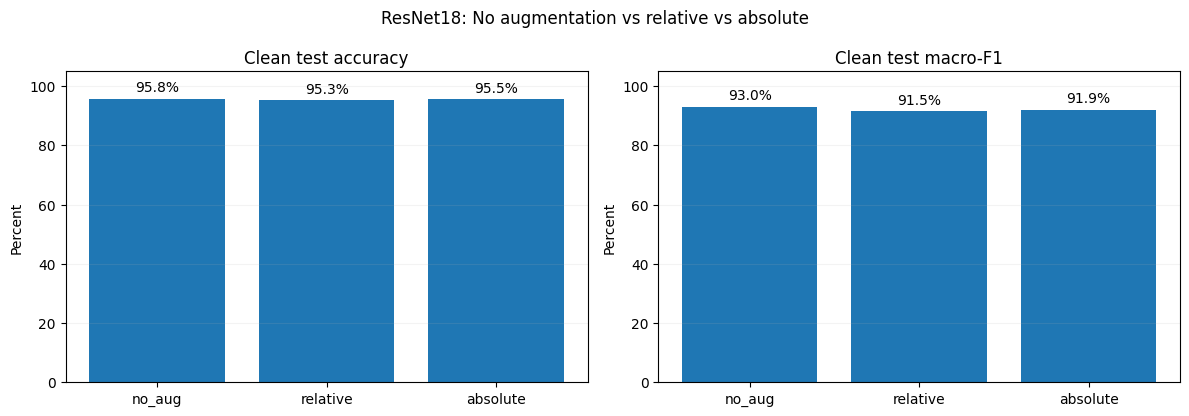

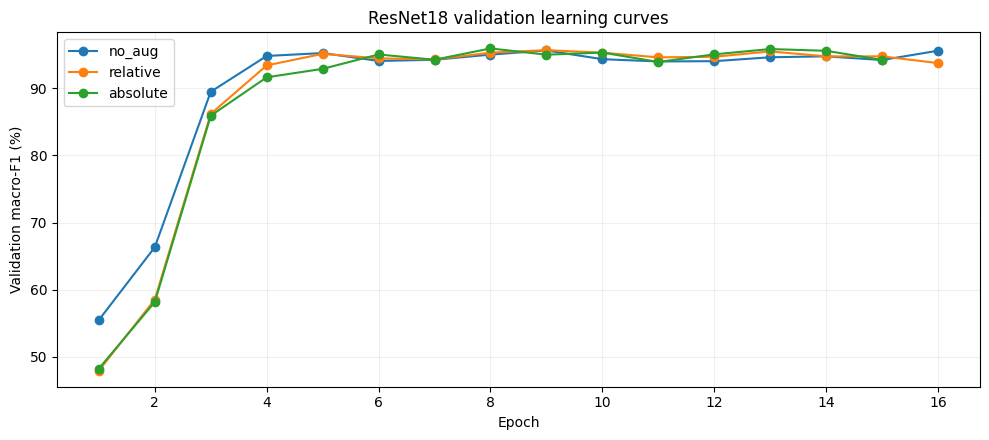

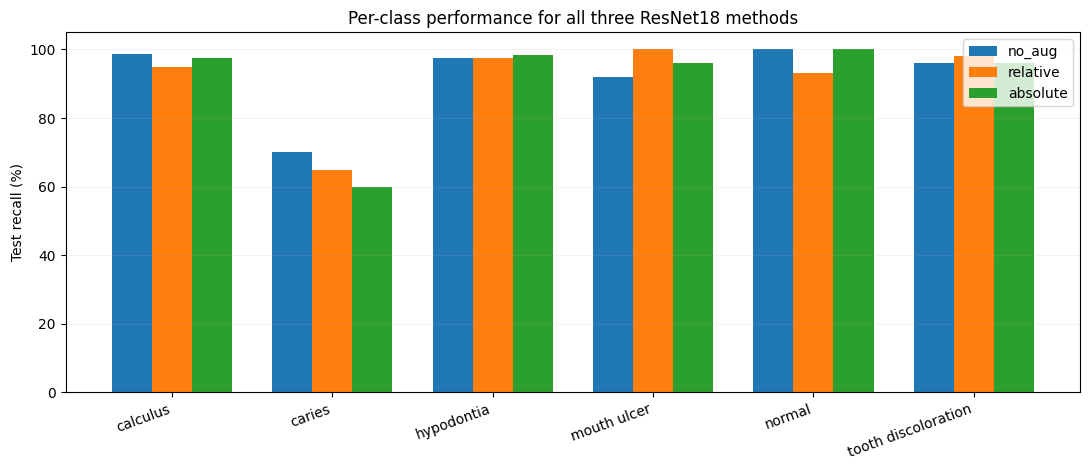

Saved all three-way results and slide figures in: /content/drive/MyDrive/26S2-AIDL-Group-7-ToothPic/models/resnet18_controlled_study_v3
Interpretation: no_aug has no stochastic photometric OR geometric augmentation.
The no_aug comparison measures the combined benefit of augmentation.
The relative-versus-absolute comparison isolates the lightness strategy.


In [49]:
arms_three = ['no_aug', 'relative', 'absolute']

# The existing relative and absolute checkpoints must already exist.
for arm in arms_three:
    assert (OUT / arm / 'best.pt').exists(), 'Missing checkpoint for ' + arm

# Evaluate clean and identical camera-stress conditions.
new_rows = []
new_recall_rows = []
y_true, y_pred, y_prob = predict_checkpoint('no_aug')
new_rows.append({'arm': 'no_aug', 'condition': 'clean',
                 'accuracy': accuracy_score(y_true, y_pred),
                 'macro_f1': f1_score(y_true, y_pred, average='macro', zero_division=0),
                 'flip_rate': 0.0})
report = classification_report(y_true, y_pred, labels=range(len(CLASSES)),
                               target_names=CLASSES, output_dict=True, zero_division=0)
for label in CLASSES:
    new_recall_rows.append({'arm': 'no_aug', 'class': label,
                            'support': report[label]['support'],
                            'precision': report[label]['precision'],
                            'recall': report[label]['recall'],
                            'f1': report[label]['f1-score']})

for condition in STRESSES:
    y, stressed_pred, _ = predict_checkpoint('no_aug', condition)
    assert np.array_equal(y, y_true)
    new_rows.append({'arm': 'no_aug', 'condition': condition,
                     'accuracy': accuracy_score(y, stressed_pred),
                     'macro_f1': f1_score(y, stressed_pred, average='macro', zero_division=0),
                     'flip_rate': float(np.mean(stressed_pred != y_pred))})

prior_scores = pd.read_csv(OUT / 'test_and_stress_scores.csv')
prior_recalls = pd.read_csv(OUT / 'test_per_class.csv')
comparison_scores = pd.concat([prior_scores, pd.DataFrame(new_rows)], ignore_index=True)
comparison_recalls = pd.concat([prior_recalls, pd.DataFrame(new_recall_rows)], ignore_index=True)
comparison_scores.to_csv(OUT / 'three_way_test_and_stress.csv', index=False)
comparison_recalls.to_csv(OUT / 'three_way_per_class.csv', index=False)

# Compare only the best validation checkpoints; do not use test to pick an epoch.
validation_rows = []
for arm in arms_three:
    hist = pd.read_csv(OUT / arm / 'history.csv')
    chosen = hist.loc[hist.val_macro_f1.idxmax()]
    validation_rows.append({'arm': arm,
                            'best_epoch': int(chosen.epoch),
                            'best_val_macro_f1': float(chosen.val_macro_f1),
                            'best_val_accuracy': float(chosen.val_accuracy)})
validation_three = pd.DataFrame(validation_rows)
validation_three.to_csv(OUT / 'three_way_validation.csv', index=False)
clean_three = comparison_scores[comparison_scores.condition == 'clean'].copy()
print('VALIDATION (for choosing models)')
display(validation_three)
print('HELD-OUT SCHOOL TEST (for reporting)')
display(clean_three[['arm', 'accuracy', 'macro_f1']].sort_values('macro_f1', ascending=False))
print('STRESS ROBUSTNESS')
display(comparison_scores[comparison_scores.condition != 'clean'].groupby('arm').agg(
    mean_stress_accuracy=('accuracy', 'mean'),
    worst_stress_accuracy=('accuracy', 'min'),
    mean_flip_rate=('flip_rate', 'mean')).reindex(arms_three))

# Slide figure 08: direct three-way clean test comparison.
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
clean_ordered = clean_three.set_index('arm').loc[arms_three]
for ax, metric, title in [
    (axes[0], 'accuracy', 'Clean test accuracy'),
    (axes[1], 'macro_f1', 'Clean test macro-F1')]:
    bars = ax.bar(arms_three, clean_ordered[metric].to_numpy() * 100)
    ax.bar_label(bars, fmt='%.1f%%', padding=3)
    ax.set_ylim(0, 105)
    ax.set_ylabel('Percent')
    ax.set_title(title)
    ax.grid(axis='y', alpha=0.15)
fig.suptitle('ResNet18: No augmentation vs relative vs absolute')
plt.tight_layout()
save_fig(OUT / 'slide_08_three_way_clean_test.png')

# Slide figure 09: show the training evidence across all three arms.
fig, ax = plt.subplots(figsize=(10, 4.5))
for arm in arms_three:
    hist = pd.read_csv(OUT / arm / 'history.csv')
    ax.plot(hist.epoch, hist.val_macro_f1 * 100, marker='o', label=arm)
ax.set_xlabel('Epoch')
ax.set_ylabel('Validation macro-F1 (%)')
ax.set_title('ResNet18 validation learning curves')
ax.grid(alpha=0.2)
ax.legend()
plt.tight_layout()
save_fig(OUT / 'slide_09_three_way_validation_curves.png')

# Slide figure 10: per-class recall, including the harder caries class.
fig, ax = plt.subplots(figsize=(11, 4.8))
x = np.arange(len(CLASSES))
for j, arm in enumerate(arms_three):
    values = comparison_recalls.set_index(['arm', 'class']).loc[
        [(arm, c) for c in CLASSES], 'recall'].to_numpy() * 100
    ax.bar(x + (j - 1) * 0.25, values, width=0.25, label=arm)
ax.set_xticks(x, [c.replace('_', ' ') for c in CLASSES], rotation=20, ha='right')
ax.set_ylim(0, 105)
ax.set_ylabel('Test recall (%)')
ax.set_title('Per-class performance for all three ResNet18 methods')
ax.grid(axis='y', alpha=0.15)
ax.legend()
plt.tight_layout()
save_fig(OUT / 'slide_10_three_way_per_class_recall.png')

print('Saved all three-way results and slide figures in:', OUT)
print('Interpretation: no_aug has no stochastic photometric OR geometric augmentation.')
print('The no_aug comparison measures the combined benefit of augmentation.')
print('The relative-versus-absolute comparison isolates the lightness strategy.')

## 12 - Slide-ready per-class and robustness comparisons

These plots report measured effects and trade-offs. Any accuracy difference of one test image is about 0.26 percentage points because there are only 382 test images.

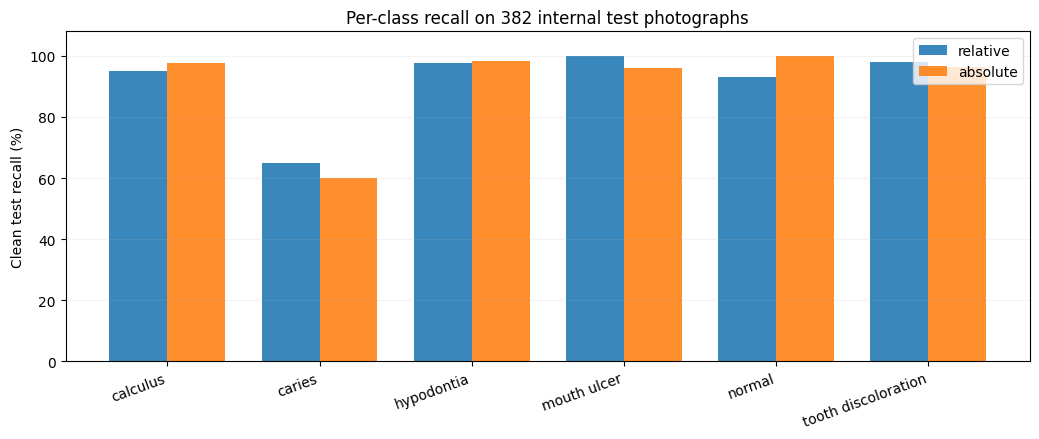

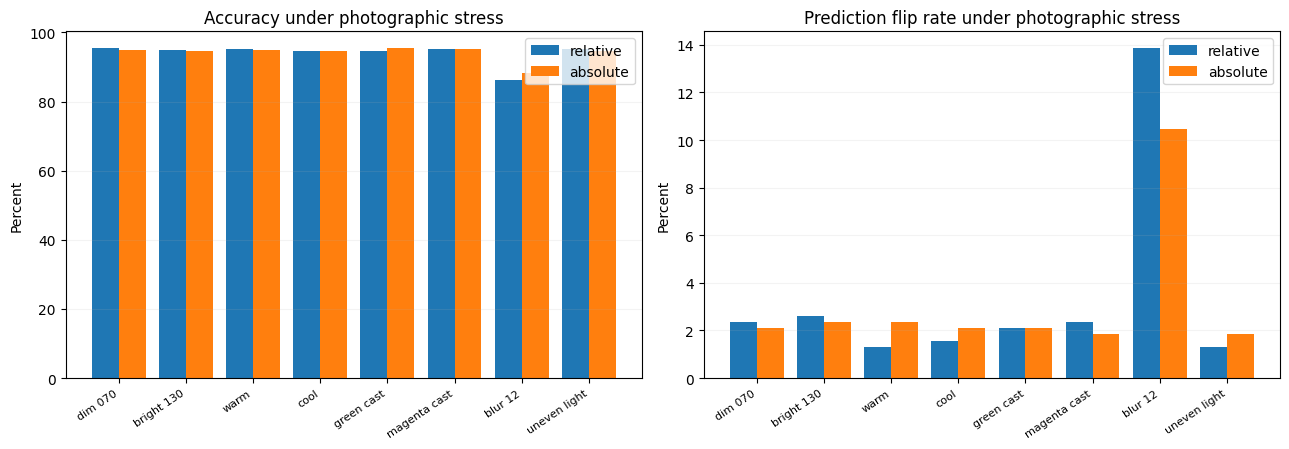

In [46]:
fig,ax=plt.subplots(figsize=(10.5,4.5))
x=np.arange(len(CLASSES))
for offset,arm in zip([-0.19,0.19],CONFIG['arms']):
    y=recalls.set_index(['arm','class']).loc[[(arm,c) for c in CLASSES],'recall'].values
    bars=ax.bar(x+offset,y*100,width=.38,label=arm,alpha=.88)
ax.set_xticks(x,[c.replace('_',' ') for c in CLASSES],rotation=20,ha='right')
ax.set_ylim(0,108)
ax.set_ylabel('Clean test recall (%)')
ax.set_title('Per-class recall on 382 internal test photographs')
ax.grid(axis='y',alpha=.15)
ax.legend()
plt.tight_layout()
save_fig(OUT/'slide_05_per_class_recall.png')

fig,axes=plt.subplots(1,2,figsize=(13,4.6))
conditions=STRESSES
for ax,metric,title in [
    (axes[0],'accuracy','Accuracy under photographic stress'),
    (axes[1],'flip_rate','Prediction flip rate under photographic stress')]:
    xi=np.arange(len(conditions))
    for offset,arm in zip([-0.20,0.20],CONFIG['arms']):
        vals=scores[(scores.arm==arm)&(scores.condition!='clean')].set_index('condition').loc[conditions,metric].values
        ax.bar(xi+offset,vals*100,width=.40,label=arm)
    ax.set_xticks(xi,[s.replace('_',' ') for s in conditions],rotation=34,ha='right',fontsize=8)
    ax.set_ylabel('Percent')
    ax.set_title(title)
    ax.grid(axis='y',alpha=.15)
    ax.legend()
plt.tight_layout()
save_fig(OUT/'slide_06_robustness_comparison.png')


## 13 - Team model comparison from saved metrics

This table reads **saved model results** from the team's Drive folder. These runs do not share identical preprocessing or tuning protocols, so use the table as a project benchmark, not a controlled architecture-only experiment.

The two new ResNet18 arms above are the controlled study.

,model,test_accuracy,test_macro_f1,source
2,EfficientNet-B0,0.965969,0.952063,models/member_3_efficientnet/metrics.json
3,Original ResNet18,0.958115,0.943902,models/training_template/metrics.json
1,MobileNetV3 Small,0.958115,0.940262,models/member_2_mobilenet/metrics.json
5,ResNet18 absolute,0.955497,0.919307,models/resnet18_controlled_study_v1/absolute/b...
4,ResNet18 relative,0.952880,0.915342,models/resnet18_controlled_study_v1/relative/b...
0,Custom CNN,0.869110,0.809617,models/member_4_custom_cnn/metrics.json


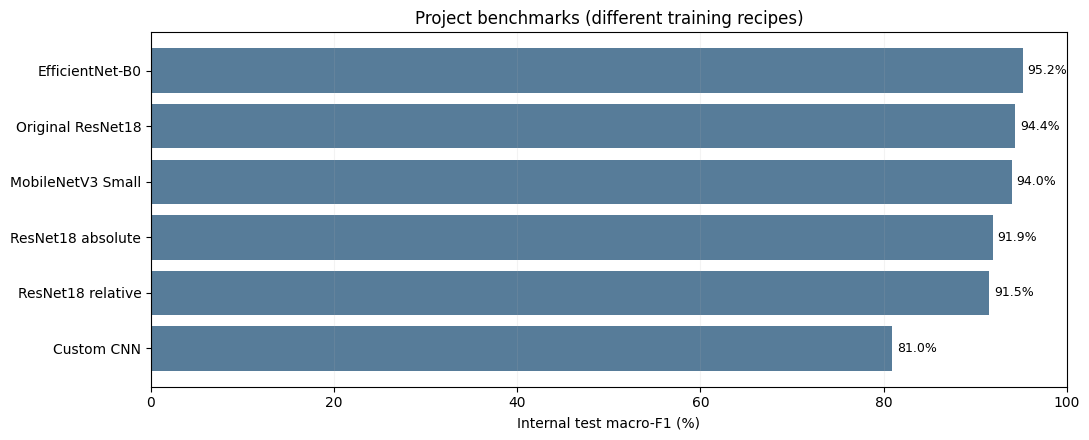

In [47]:
OTHER_MODELS={
    'Custom CNN':ROOT/'models/member_4_custom_cnn/metrics.json',
    'MobileNetV3 Small':ROOT/'models/member_2_mobilenet/metrics.json',
    'EfficientNet-B0':ROOT/'models/member_3_efficientnet/metrics.json',
    'Original ResNet18':ROOT/'models/training_template/metrics.json',
}
team_rows=[]
for name,path in OTHER_MODELS.items():
    if not path.exists():
        print('Missing team metrics:',path)
        continue
    d=json.loads(path.read_text(encoding='utf-8'))
    team_rows.append({'model':name,
                      'test_accuracy':float(d.get('test_accuracy',d.get('classification_report',{}).get('accuracy',0))),
                      'test_macro_f1':float(d['test_macro_f1']),
                      'source':str(path.relative_to(ROOT))})
for arm in CONFIG['arms']:
    metrics=scores[(scores.arm==arm)&(scores.condition=='clean')].iloc[0]
    team_rows.append({'model':'ResNet18 '+arm,
                      'test_accuracy':float(metrics.accuracy),
                      'test_macro_f1':float(metrics.macro_f1),
                      'source':'models/resnet18_controlled_study_v1/'+arm+'/best.pt'})
team=pd.DataFrame(team_rows).sort_values('test_macro_f1',ascending=False)
team.to_csv(OUT/'team_model_comparison.csv',index=False)
display(team)
fig,ax=plt.subplots(figsize=(11,4.5))
ax.barh(team.model.iloc[::-1],team.test_macro_f1.iloc[::-1]*100,color='#577c99')
ax.set_xlabel('Internal test macro-F1 (%)')
ax.set_xlim(0,100)
ax.grid(axis='x',alpha=.15)
ax.set_title('Project benchmarks (different training recipes)')
for i,v in enumerate(team.test_macro_f1.iloc[::-1]*100):
    ax.text(v+0.5,i,f'{v:.1f}%',va='center',fontsize=9)
plt.tight_layout()
save_fig(OUT/'slide_07_team_model_comparison.png')

## 14 - Generate a presentation summary with defensible claims

Use the generated text as speaking notes. The study may favour either method. Do not write an improvement claim until the measured data supports it.

What we **can** say:

- Two ResNet18 training arms used identical data splits, geometry, model setup, initialization and optimization. The lightness-target sampling policy is the controlled variable.
- The boxplots measure actual global image-lightness distributions.
- The pixel-only probe deliberately excludes file size and original dimensions; even a high score does not prove what ResNet18 learned.
- The stress tests compare prediction stability on the same source photographs.

What we **cannot** say:

- That Random Forest metadata features are directly available to ResNet18.
- That reducing global colour predictability is always desirable for dental images.
- That good internal test accuracy proves generalization to new phones or patients.
- That a difference of a few test images establishes a reliable improvement without repeat seeds and external data.

In [48]:
from scipy.stats import binomtest

paired_predictions = pd.DataFrame(all_predictions).pivot(index='row_index', columns='arm', values='correct')
a = paired_predictions['absolute'].to_numpy(dtype=bool)
b = paired_predictions['relative'].to_numpy(dtype=bool)
abs_only_correct = int(np.sum(a & ~b))
rel_only_correct = int(np.sum(b & ~a))
discordant = abs_only_correct + rel_only_correct
p_value = float(binomtest(abs_only_correct, discordant, 0.5).pvalue) if discordant else 1.0
paired_rng = np.random.default_rng(42)
indices = paired_rng.integers(0, len(a), size=(5000, len(a)))
deltas = (a[indices].mean(axis=1) - b[indices].mean(axis=1)) * 100
ci_lo, ci_hi = np.quantile(deltas, [0.025, 0.975])
paired_summary = {
    'absolute_only_correct': abs_only_correct,
    'relative_only_correct': rel_only_correct,
    'mcnemar_exact_p': p_value,
    'paired_accuracy_delta_percentage_points_ci95': [float(ci_lo),float(ci_hi)],
    'notes': 'Paired internal test bootstrap and exact McNemar test. Descriptive after validation selection.'
}
save_json(OUT/'paired_model_comparison.json',paired_summary)

clean=scores[scores.condition=='clean'].set_index('arm')
stress=scores[scores.condition!='clean'].groupby('arm').agg(
    mean_stress_accuracy=('accuracy','mean'),
    worst_stress_accuracy=('accuracy','min'),
    mean_flip_rate=('flip_rate','mean'))
relative=clean.loc['relative']
absolute=clean.loc['absolute']
metrics_lines=[
    'TOOTHPIC - CONTROLLED RESNET18 PHOTOMETRIC STUDY',
    '',
    'Research question: Does class-independent absolute lightness targeting outperform relative jitter?',
    'Controlled variable: Lab L target selection, with identical Lab a/b sampling and spatial transforms.',
    'Selection criterion: validation macro-F1; winner = '+WINNER,
    '',
    'CLEAN INTERNAL TEST (n=382)',
    f'Relative: accuracy {relative.accuracy*100:.2f}%, macro-F1 {relative.macro_f1*100:.2f}%',
    f'Absolute: accuracy {absolute.accuracy*100:.2f}%, macro-F1 {absolute.macro_f1*100:.2f}%',
    f'Absolute minus relative accuracy: {(absolute.accuracy-relative.accuracy)*100:+.2f} percentage points',
    f'Absolute minus relative macro-F1: {(absolute.macro_f1-relative.macro_f1)*100:+.2f} percentage points',
    f'Paired 95% bootstrap CI for accuracy difference: [{ci_lo:+.2f}, {ci_hi:+.2f}] percentage points',
    f'Exact McNemar p-value: {p_value:.4f} (absolute-only correct {abs_only_correct}; relative-only correct {rel_only_correct})',
    '',
    'STRESS TEST',
]
for arm in CONFIG['arms']:
    r=stress.loc[arm]
    metrics_lines.append(f'{arm}: mean accuracy {r.mean_stress_accuracy*100:.2f}%, '
                         f'worst accuracy {r.worst_stress_accuracy*100:.2f}%, '
                         f'prediction flip rate {r.mean_flip_rate*100:.2f}%')
metrics_lines.extend([
    '',
    'DATA AND TRAINING',
    '3795 prepared images: train 3035, validation 378, test 382.',
    'ResNet18 with ImageNet pretrained weights, six-class head, 2-epoch head warmup, full fine-tuning.',
    'Inverse-square-root class weights, AdamW, cosine decay, AMP and validation checkpoint selection.',
    'Lab a/b color-cast randomization, clipping protection and letterboxing are shared across arms.',
    '',
    'LIMITATIONS',
    'Original JPEG size and width are not direct ResNet18 inputs.',
    'Both models were evaluated on an internal school split already used in prior experiments.',
    'Class colors can be clinically informative. A lower pixel-only probe score is not always better.',
    'Potential near-duplicates and unknown patient/device overlap require independent validation.',
    'Letterbox padding preserves an aspect-ratio cue, although both new arms use identical padding.',
    '',
    'SLIDE IMAGE FILES',
    'slide_01_relative_vs_absolute_boxplots.png',
    'slide_02_augmentation_previews.png',
    'slide_03_validation_learning_curves.png',
    'slide_04_test_confusion_matrices.png',
    'slide_05_per_class_recall.png',
    'slide_06_robustness_comparison.png',
    'slide_07_team_model_comparison.png',
])
report='\n'.join(metrics_lines)+'\n'
(OUT/'presentation_summary.txt').write_text(report,encoding='ascii')
print(report)

TOOTHPIC - CONTROLLED RESNET18 PHOTOMETRIC STUDY

Research question: Does class-independent absolute lightness targeting outperform relative jitter?
Controlled variable: Lab L target selection, with identical Lab a/b sampling and spatial transforms.
Selection criterion: validation macro-F1; winner = absolute

CLEAN INTERNAL TEST (n=382)
Relative: accuracy 95.29%, macro-F1 91.53%
Absolute: accuracy 95.55%, macro-F1 91.93%
Absolute minus relative accuracy: +0.26 percentage points
Absolute minus relative macro-F1: +0.40 percentage points
Paired 95% bootstrap CI for accuracy difference: [-1.57, +1.83] percentage points
Exact McNemar p-value: 1.0000 (absolute-only correct 6; relative-only correct 5)

STRESS TEST
relative: mean accuracy 94.01%, worst accuracy 86.13%, prediction flip rate 3.44%
absolute: mean accuracy 94.14%, worst accuracy 88.22%, prediction flip rate 3.14%

DATA AND TRAINING
3795 prepared images: train 3035, validation 378, test 382.
ResNet18 with ImageNet pretrained weight

## 15 - Presentation and code walkthrough checklist

A five-minute explanation can follow this order:

1. **0:00-0:40:** Six-class dataset, class imbalance, and why photographic style is a concern. Distinguish RF metadata correlations from ResNet18 inputs.
2. **0:40-1:50:** Two boxplots from real training photographs; compare per-image relative targets with common class-independent absolute targets.
3. **1:50-3:00:** Walk through `shift_lab_content()` and `train_arm()`: preserving colour cues, shared a/b policy, letterbox, pretrained ResNet18, staged fine-tuning, loss, optimizer, cosine schedule and AMP.
4. **3:00-4:15:** Show validation-selected checkpoint and the actual comparative test metrics. Interpret per-class recall and prediction stability, including any negative results.
5. **4:15-5:00:** Explain the limitations, near-duplicate concern, and the need for independent phone photographs.

Code-review questions to practice:

- Why are only training photographs used to calibrate the augmentation targets?
- What exactly differs between `relative` and `absolute` arms?
- Why freeze the backbone for two epochs, then fine-tune it?
- Why choose a checkpoint by validation macro-F1 instead of test accuracy?
- Why are file size and original dimensions excluded from the pixel-only RF probe?
- What might a low caries recall mean when the test split includes only 20 caries examples?
- Why can boxplot overlap alone not establish better dental recognition?

References for the general idea: RandStainNA (2022, https://arxiv.org/abs/2206.12694), MixStyle (2021, https://arxiv.org/abs/2104.02008), and DomainBed (2021, https://arxiv.org/abs/2007.01434). These motivate style randomization and fair comparisons; they do not validate ToothPic-specific hyperparameters.